# Funding overview

How do recorded funding, requests and recipient locations vary?

**Scope:** All cleaned funding records for 2020-2025, before the comparative legal-form filter. Most measures use recipient-year records; annual counts use unique recipient codes within each year.

This overview covers all cleaned recipient-year records before the comparative legal-form cohort is applied. PMD refers here to calculated GPM support funding in euros. An annual record is not the same as a unique recipient across the whole period.

The [Methodology](../METHODOLOGY.md) documents definitions and correction policies. The [Project overview](../README.md) describes the notebook sequence and dataset rebuild process.

## Analysis inputs

The analysis loads the cleaned funding data and shared chart theme.

In [ ]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Locate the checkout from the project folder or a notebook subfolder.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "analysis_helpers.py").is_file()
     and (p / "config" / "sources.yaml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project folder.")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from chart_style import apply_chart_style, colors_from_style, growth_cmap_from_style, load_chart_style

chart_style = load_chart_style(PROJECT_ROOT)
apply_chart_style(chart_style)
CHART_COLORS = colors_from_style(chart_style)
GROWTH_CMAP = growth_cmap_from_style(chart_style)
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

vmi = pd.read_csv(INTERIM_DIR / "vmi_support_by_recipient.csv", low_memory=False, dtype={"recipient_code": "string"})

vmi["recipient_code"] = vmi["recipient_code"].astype("string").str.strip()
vmi["legal_form_clean"] = vmi["legal_form"].fillna("Unknown").str.strip()


vmi.head()


,tax_year,recipient_municipality,recipient_code,recipient_name,legal_form,requests,calculated_pmd_eur,legal_form_clean
0,2025,Kauno m. sav.,191678556,Socialinių inovacijų fondas,Labdaros ir paramos fondas,7,604.80,Labdaros ir paramos fondas
1,2025,Plungės r. sav.,170075590,"Sporto klubas ""Makabi""",Asociacija,4,192.18,Asociacija
2,2025,Kauno m. sav.,193158860,Moters užimtumo informacijos centras,Asociacija,4,316.10,Asociacija
3,2025,Vilniaus m. sav.,124467262,"Paramos fondas ""Švietimo ir tyrimų institutas""",Labdaros ir paramos fondas,19,985.02,Labdaros ir paramos fondas
4,2025,Jurbarko r. sav.,191250833,Skirsnemunės Šv. Jurgio parapija,Tradicinė religinė bendruomenė ar bendrija,9,788.37,Tradicinė religinė bendruomenė ar bendrija


## Shared analysis data and missing-value policy

Every analysis uses one validated record per recipient and tax year for 2020-2025. Recipient codes identify organizations; names are display fields. Duplicate keys, invalid years, negative amounts and invalid request counts stop execution for review.

Recorded zeros remain zero. Missing amounts and request counts remain unknown. A total is unavailable if any contributing value is missing. Medians and maxima describe known observations; the coverage table reports their available funding sample. Missing requests are not classified as zero requests.

Municipality totals use this same data and policy. Missing municipality labels appear as Unknown; incomplete funding totals remain in the table but are excluded from the ranking. Median annual municipal recipient counts use years with observed records, without inventing zero counts for absent years. No source files are modified.

In [2]:
from IPython.display import display

ANALYSIS_YEARS = list(range(2020, 2026))

def complete_total(values):
    """An empty or incomplete total is unknown, not zero."""
    return values.sum(min_count=max(1, len(values)))

def prepare_overview_data(source, years):
    data = source.copy()
    parsed_years = pd.to_numeric(data['tax_year'], errors='coerce')
    if (parsed_years.isna() | ~np.isfinite(parsed_years) | parsed_years.mod(1).ne(0)).any():
        raise ValueError('Missing or invalid tax years require review.')
    data['tax_year'] = parsed_years.astype(int)
    data = data.loc[data['tax_year'].isin(years)].copy()
    data['recipient_code'] = data['recipient_code'].astype('string').str.strip()
    if (data['recipient_code'].isna() | data['recipient_code'].eq('')).any():
        raise ValueError('Missing recipient codes require review.')
    keys = ['recipient_code', 'tax_year']
    duplicates = data.loc[data.duplicated(keys, keep=False)]
    if not duplicates.empty:
        display(duplicates.sort_values(keys))
        raise ValueError('Duplicate recipient-year keys require review; no rows were combined.')
    for column in ['calculated_pmd_eur', 'requests']:
        raw = data[column]
        numeric = pd.to_numeric(raw, errors='coerce')
        invalid = ((raw.notna() & numeric.isna())
                   | (numeric.notna() & ~np.isfinite(numeric)) | numeric.lt(0))
        if column == 'requests':
            invalid |= numeric.notna() & numeric.mod(1).ne(0)
        if invalid.any():
            display(data.loc[invalid, keys + [column]])
            raise ValueError(f'Invalid {column} values require review.')
        data[column] = numeric
    missing_years = set(years) - set(data['tax_year'])
    if missing_years:
        raise ValueError(f'Missing analysis years: {sorted(missing_years)}')
    data = data.rename(columns={'calculated_pmd_eur': 'amount'})
    data['amount_per_request'] = data['amount'].div(data['requests'].where(data['requests'].gt(0)))
    return data.sort_values(keys).reset_index(drop=True)

overview_recipient_year = prepare_overview_data(vmi, ANALYSIS_YEARS)
coverage = overview_recipient_year.groupby('tax_year').agg(
    recipients=('recipient_code', 'nunique'),
    known_amounts=('amount', 'count'),
    missing_amounts=('amount', lambda s: s.isna().sum()),
    known_requests=('requests', 'count'),
    missing_requests=('requests', lambda s: s.isna().sum()),
)
display(coverage.rename_axis('Year').style.format('{:,.0f}'))


,recipients,known_amounts,missing_amounts,known_requests,missing_requests
Year,,,,,
2020,"23,240","23,240",0,"23,240",0
2021,"22,798","22,798",0,"22,798",0
2022,"22,147","22,147",0,"22,147",0
2023,"22,555","22,555",0,"22,555",0
2024,"14,511","14,511",0,"14,511",0
2025,"15,483","15,483",0,"15,483",0


### Which years are included?

This check confirms that the shared analysis table contains exactly the six intended years. It stops execution if the observed period differs from the configured period.

In [3]:
observed_years = sorted(
    overview_recipient_year["tax_year"].unique().tolist()
)

assert observed_years == ANALYSIS_YEARS, (
    f"Expected {ANALYSIS_YEARS}, found {observed_years}"
)

print(
    f"Analysis period: {observed_years[0]}–{observed_years[-1]}"
)
print(f"Years included: {observed_years}")

Analysis period: 2020–2025
Years included: [2020, 2021, 2022, 2023, 2024, 2025]


## How do annual totals differ?

The table summarizes recorded recipients, requests and funding for each year.

- **Average funding:** funding summed across recipients with known amounts, divided by their number. Large amounts can pull this measure upward.
- **Median funding:** the middle recipient funding amount, providing a useful description of typical funding.
- **25th and 75th percentiles:** the approximate boundaries of the middle half of recipient funding amounts.
- **Highest funding:** the largest known amount received by one recipient that year.

Recorded zeros are included. Average, median and percentile calculations exclude missing funding values; “Known funding” reports the number of recipients used. Annual funding and request totals remain unavailable if any contributing value is missing.

In [22]:
yearly_summary = (
    overview_recipient_year.groupby("tax_year")
    .agg(
        recipients=("recipient_code", "nunique"),
        requests=("requests", complete_total),
        total_pmd_eur=("amount", complete_total),
        mean_pmd_eur=("amount", "mean"),
        median_pmd_eur=("amount", "median"),
        p25_pmd_eur=("amount", lambda s: s.quantile(0.25)),
        p75_pmd_eur=("amount", lambda s: s.quantile(0.75)),
        highest_pmd_eur=("amount", "max"),
        recipients_with_known_funding=("amount", "count"),
        recipients_with_known_requests=("requests", "count"),
    )
    .reindex(ANALYSIS_YEARS)
    .rename_axis("tax_year")
    .reset_index()
)

# Presentation labels do not change the columns used by later charts.
annual_display = yearly_summary.rename(columns={
    "tax_year": "Year",
    "recipients": "Recorded recipients",
    "requests": "Total requests",
    "total_pmd_eur": "Total funding",
    "mean_pmd_eur": "Average funding",
    "median_pmd_eur": "Median funding",
    "p25_pmd_eur": "25th percentile",
    "p75_pmd_eur": "75th percentile",
    "highest_pmd_eur": "Highest funding",
    "recipients_with_known_funding": "Known funding",
    "recipients_with_known_requests": "Known request counts",
})

money_columns = [
    "Total funding",
    "Average funding",
    "Median funding",
    "25th percentile",
    "75th percentile",
    "Highest funding",
]

formats = {
    column: "{:,.0f} €"
    for column in money_columns
}
formats.update({
    "Year": "{:.0f}",
    "Recorded recipients": "{:,.0f}",
    "Total requests": "{:,.0f}",
    "Known funding": "{:,.0f}",
    "Known request counts": "{:,.0f}",
})

display(
    annual_display.style
    .format(formats, na_rep="Unavailable")
    .hide(axis="index")
)


Year,Recorded recipients,Total requests,Total funding,Average funding,Median funding,25th percentile,75th percentile,Highest funding,Known funding,Known request counts
2020,"23,240","560,324","21,654,753 €",932 €,266 €,100 €,680 €,"402,650 €","23,240","23,240"
2021,"22,798","604,259","27,843,176 €","1,221 €",305 €,113 €,783 €,"2,139,129 €","22,798","22,798"
2022,"22,147","574,934","29,202,852 €","1,319 €",340 €,126 €,885 €,"1,892,070 €","22,147","22,147"
2023,"22,555","597,309","33,985,135 €","1,507 €",380 €,142 €,958 €,"2,377,593 €","22,555","22,555"
2024,"14,511","591,434","36,904,168 €","2,543 €",592 €,237 €,"1,379 €","3,068,048 €","14,511","14,511"
2025,"15,483","652,119","40,124,625 €","2,592 €",604 €,230 €,"1,377 €","2,732,929 €","15,483","15,483"


### Total funding by year

The chart shows total calculated PMD across all recorded recipients in each year. Changes reflect both funding received by individual organizations and changes in the recipient population.

An annual total is unavailable if any contributing funding amount is missing.

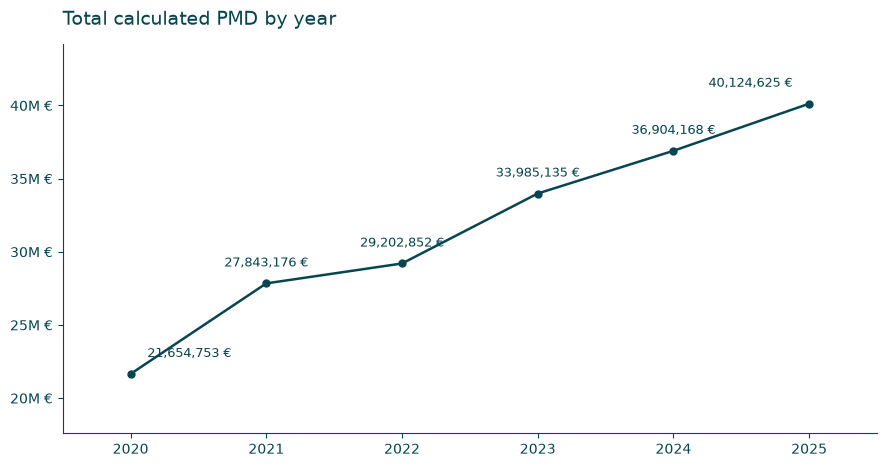

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from chart_style import finish_chart

annual_funding = (
    yearly_summary
    .set_index("tax_year")["total_pmd_eur"]
    .reindex(ANALYSIS_YEARS)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    annual_funding.index,
    annual_funding,
    marker="o",
    color=CHART_COLORS["primary"],
)

for year, amount in annual_funding.dropna().items():
    first_year = year == ANALYSIS_YEARS[0]
    last_year = year == ANALYSIS_YEARS[-1]

    ax.annotate(
        f"{amount:,.0f} €",
        xy=(year, amount),
        xytext=(
            12 if first_year else -12 if last_year else 0,
            10,
        ),
        textcoords="offset points",
        ha="left" if first_year else "right" if last_year else "center",
        va="bottom",
        fontsize=9,
        color=CHART_COLORS["foreground"],
    )

ax.set_title("Total calculated PMD by year")
ax.set_xticks(ANALYSIS_YEARS)
ax.set_ylabel("")
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, pos:
        f"{value / 1_000_000:,.1f}".rstrip("0").rstrip(".") + "M €"
    )
)
ax.grid(False, which="both")
ax.margins(x=0.10, y=0.22)

finish_chart(fig)

### What the chart shows

Total recorded funding increased from **€21.65 million in 2020 to €40.12 million in 2025**, a rise of approximately **85.3%**.

Funding increased every year. In **2025**, it rose by approximately **€3.22 million (8.7%)**, reaching its highest level in the period.

### Main takeaway

Total funding grew despite the decline in recorded recipient numbers across the six years. This does not mean every organization received more: changes in individual funding and in the recipient population both contribute to the annual totals.

**Note:** Amounts are not adjusted for inflation. The chart shows funding received by organizations, not the number of unique supporters.

## How much PMD was recorded across all six years?

The table shows total calculated PMD for 2020–2025 across all cleaned funding records, before the comparative legal-form filter. 

In [6]:
period_data = overview_recipient_year

six_year_summary = pd.DataFrame({
    "Period": ["2020–2025"],
    "Unique recipients": [period_data["recipient_code"].nunique()],
    "Recipient-year records": [len(period_data)],
    "Total calculated PMD": [complete_total(period_data["amount"])],
})

def format_euros(value):
    return f"{value:,.2f}".rstrip("0").rstrip(".") + " €"

display(
    six_year_summary.style
    .format({
        "Unique recipients": "{:,}",
        "Recipient-year records": "{:,}",
        "Total calculated PMD": format_euros,
    }, na_rep="Unavailable")
    .hide(axis="index")
)

Period,Unique recipients,Recipient-year records,Total calculated PMD
2020–2025,"30,779","120,734","189,714,709.34 €"


## Annual recipient and funding trends

The following sections use the shared annual summary to examine recipient counts, requests, typical funding and the largest funding amounts separately. The common plotting function keeps the theme, number formatting and label positions consistent. It prepares the presentation only; it does not recalculate the data.

Each chart is followed by its interpretation. Axis ranges are scaled independently and may not start at zero.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from chart_style import finish_chart

def readable_number(value, decimals=0):
    text = f"{value:,.{decimals}f}"
    return text.rstrip("0").rstrip(".") if decimals else text

def plot_annual_overview(column, title, decimals, suffix, below_years):
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        yearly_summary["tax_year"],
        yearly_summary[column],
        marker="o",
        color=CHART_COLORS["primary"],
    )

    ax.set_title(title)
    ax.set_ylabel("")
    ax.set_xticks(range(2020, 2026))
    ax.grid(False, which="both")

    if column == "highest_pmd_eur":
        ax.yaxis.set_major_formatter(
            FuncFormatter(
                lambda value, pos:
                readable_number(value / 1_000_000, 2) + "M €"
            )
        )
    else:
        ax.yaxis.set_major_formatter(
            FuncFormatter(
                lambda value, pos, d=decimals, s=suffix:
                readable_number(value, d) + s
            )
        )

    observed = yearly_summary.dropna(subset=[column])

    for i, (_, row) in enumerate(observed.iterrows()):
        below = int(row["tax_year"]) in below_years
        first_point = i == 0
        last_point = i == len(observed) - 1

        horizontal_offset = 12 if first_point else 0
        if column == "highest_pmd_eur" and last_point:
            horizontal_offset = -12

        ax.annotate(
            readable_number(row[column], decimals) + suffix,
            xy=(row["tax_year"], row[column]),
            xytext=(horizontal_offset, -12 if below else 10),
            textcoords="offset points",
            ha="left" if first_point else "right",
            va="top" if below else "bottom",
            fontsize=9,
            color=CHART_COLORS["foreground"],
        )

    ax.margins(x=0.10, y=0.22)

    finish_chart(fig)

### How many recipients are recorded each year?

The chart counts distinct recipient codes within each year, including recipients with zero recorded funding. It describes annual populations, not a fixed group of organizations.

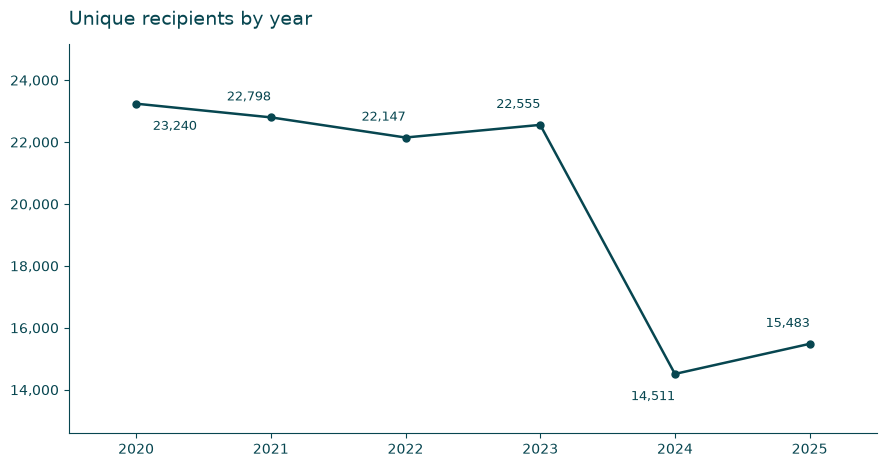

In [8]:
plot_annual_overview('recipients', 'Unique recipients by year', 0, '', {2024, 2020})

### What the recipient chart shows

Counts stayed around 22,000-23,000 during 2020-2023, then fell from **22,555 to 14,511 in 2024 (35.7%)**. They increased to **15,483 in 2025 (6.7%)**.

**Main takeaway:** The 2024 break changes the population being compared. The [legal-form analysis](03_legal_forms_analysis.ipynb) provides the context; this chart alone does not establish why individual recipients disappeared.

### How many requests are recorded each year?

The chart sums recorded request counts for each year. Requests are not necessarily unique supporters. A total is unavailable if any contributing request count is missing.

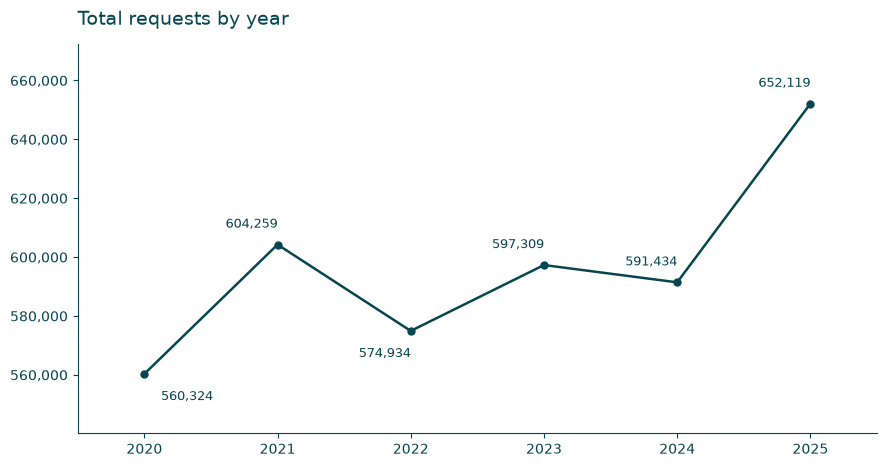

In [23]:
plot_annual_overview('requests', 'Total requests by year', 0, '', {2020, 2022})

### What the requests chart shows

Requests increased from **560,324 in 2020 to 652,119 in 2025 (16.4%)**. The strongest annual increase occurred in 2025: **60,685 additional requests (10.3%)**. In 2024, requests fell by only **1.0%**, despite the much larger drop in recorded recipients.

**Main takeaway:** Recorded request activity reached its highest level in 2025. 

### How much funding does a typical recipient receive?

The median is the middle annual funding amount among recipients with known funding, including zeros. It is an amount per recipient, not per request. The annual coverage table reports the known-funding sample.

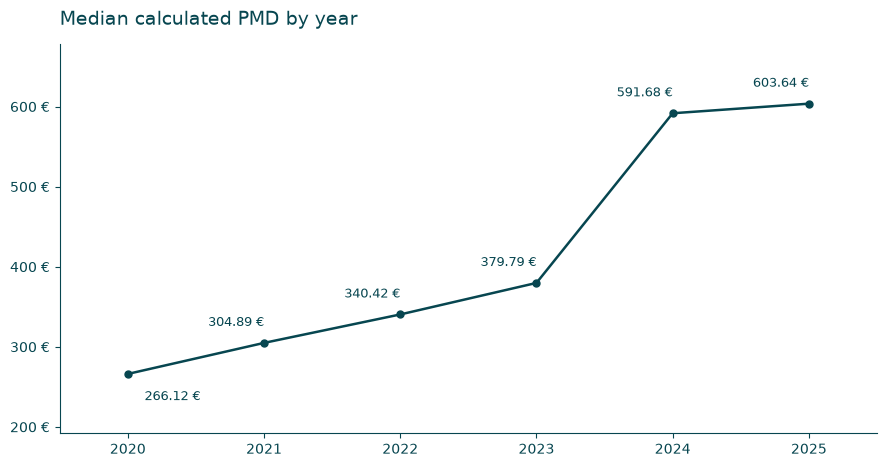

In [10]:
plot_annual_overview('median_pmd_eur', 'Median calculated PMD by year', 2, ' €', {2020})

### What the median-funding chart shows

Median annual funding rose from **EUR 266 in 2020 to EUR 380 in 2023**, then to **EUR 592 in 2024** and **EUR 604 in 2025**. The largest increase was in 2024; growth slowed to approximately **2.0%** in 2025.

**Main takeaway:** Typical recorded annual funding more than doubled across the period. Changing recipient populations mean this is not necessarily growth within the same organizations. Amounts are not adjusted for inflation.

### What is the highest annual funding per recipient?

The chart shows the largest known funding amount received by one recipient in each year. The leading organization may change, so the line is not necessarily one organization's growth history.

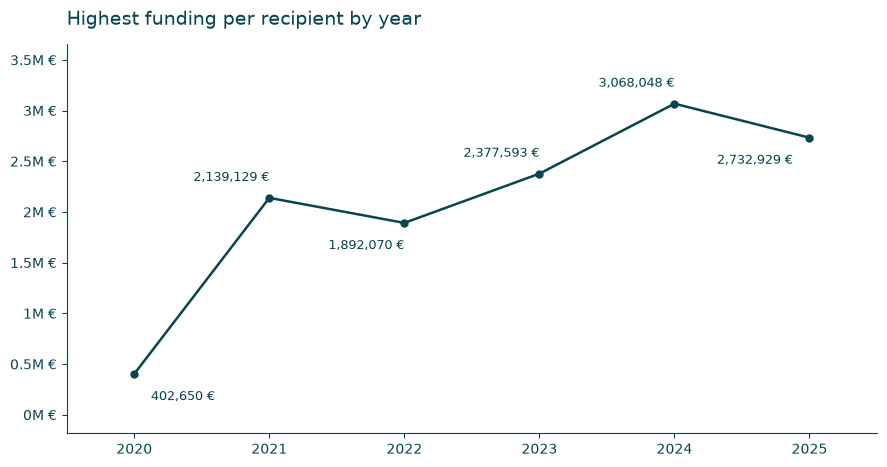

In [11]:
plot_annual_overview('highest_pmd_eur', 'Highest funding per recipient by year', 0, ' €', {2025, 2020, 2022})

### What the maximum-funding chart shows

The maximum rose from approximately **EUR 403,000 in 2020** to **EUR 3.07 million in 2024**, then fell by **10.9%** to **EUR 2.73 million in 2025**.

**Main takeaway:** The largest amount fell in 2025 while median recipient funding rose slightly. The annual-leader table below identifies the organizations behind these points; the maximum alone does not measure funding concentration.

### How many requests does a typical recipient receive?

The median shows the middle request count among recipients with known counts. The percentages use all recorded recipients in each year, including zero-request recipients. Unknown counts are reported separately, not treated as zero. Exactly one request is a subset of at least one request, so those percentages must not be added together. Requests are not necessarily unique supporters.

In [12]:
request_profile = overview_recipient_year.groupby('tax_year').agg(
    total_recipients=('recipient_code', 'nunique'),
    median_requests=('requests', 'median'),
    zero_requests=('requests', lambda s: s.eq(0).sum()),
    one_request=('requests', lambda s: s.eq(1).sum()),
    positive_requests=('requests', lambda s: s.gt(0).sum()),
    missing_requests=('requests', lambda s: s.isna().sum()),
).reindex(range(2020, 2026))
for field in ['zero_requests', 'one_request', 'positive_requests', 'missing_requests']:
    request_profile[field + '_share'] = request_profile[field] / request_profile['total_recipients']
assert (request_profile[['zero_requests', 'positive_requests', 'missing_requests']].sum(axis=1)
        == request_profile['total_recipients']).all()
request_profile_display = request_profile[[
    'total_recipients', 'median_requests', 'zero_requests_share',
    'one_request_share', 'positive_requests_share', 'missing_requests',
]].rename(columns={
    'total_recipients': 'Recorded recipients', 'median_requests': 'Median requests',
    'zero_requests_share': 'Zero requests', 'one_request_share': 'Exactly one request',
    'positive_requests_share': 'At least one request', 'missing_requests': 'Unknown requests',
}).rename_axis('Year')
display(request_profile_display.style.format({
    'Recorded recipients': '{:,.0f}', 'Median requests': lambda x: f'{x:,.1f}'.rstrip('0').rstrip('.'),
    'Zero requests': '{:.1%}', 'Exactly one request': '{:.1%}',
    'At least one request': '{:.1%}', 'Unknown requests': '{:,.0f}',
}, na_rep='Unavailable'))


,Recorded recipients,Median requests,Zero requests,Exactly one request,At least one request,Unknown requests
Year,,,,,,
2020,"23,240",7,0.0%,12.5%,100.0%,0
2021,"22,798",7,0.1%,12.0%,99.9%,0
2022,"22,147",7,0.1%,12.4%,99.9%,0
2023,"22,555",7,0.1%,12.0%,99.9%,0
2024,"14,511",9,0.1%,7.9%,99.9%,0
2025,"15,483",9,0.0%,8.3%,100.0%,0


### What the request-profile table shows

Median requests remained at **7 during 2020-2023**, then rose to **9 in 2024-2025**. The share with exactly one request fell from **12.5% in 2020 to 8.3% in 2025**.

**Main takeaway:** The middle request count increased modestly; total request growth does not describe every recipient. Small percentages rounded to 0.0% do not necessarily mean no records.

### Which recipients received the highest annual funding?

This table identifies the organizations behind the annual maximum-funding chart. Each recipient is grouped by code; the last available name within that year is displayed. All tied leaders are retained. Funding per request is unavailable when the request count is zero or missing. The leaders may change between years, so this is not a single organization's growth history.

In [13]:
annual_maximum = overview_recipient_year.groupby('tax_year')['amount'].transform('max')
annual_leaders = overview_recipient_year.loc[
    overview_recipient_year['amount'].notna()
    & overview_recipient_year['amount'].eq(annual_maximum)
].copy()
# Names remain display fields; all tied leaders are retained.
annual_leaders['average_per_request'] = annual_leaders['amount'].div(
    annual_leaders['requests'].where(annual_leaders['requests'].gt(0)))
annual_leaders = annual_leaders.sort_values(['tax_year', 'recipient_code'])
leader_display = annual_leaders[[
    'tax_year', 'recipient_name', 'recipient_code', 'amount', 'requests', 'average_per_request'
]].rename(columns={
    'tax_year': 'Year', 'recipient_name': 'Recipient', 'recipient_code': 'Code',
    'amount': 'Funding (EUR)', 'requests': 'Requests',
    'average_per_request': 'Average per request (EUR)',
})
def overview_euros(value):
    return f'{value:,.2f}'.rstrip('0').rstrip('.') + ' EUR'
display(leader_display.style.format({
    'Year': '{:.0f}', 'Funding (EUR)': overview_euros,
    'Requests': '{:,.0f}', 'Average per request (EUR)': overview_euros,
}, na_rep='Unavailable').format(escape='html', subset=['Recipient', 'Code']).hide(axis='index'))


Year,Recipient,Code,Funding (EUR),Requests,Average per request (EUR)
2020,"Paramos ir labdaros fondas ""Mamų unija""",302288579,"402,650.06 EUR","10,311",39.05 EUR
2021,"VšĮ ""Mėlyna ir geltona""",303420560,"2,139,129.25 EUR","33,447",63.96 EUR
2022,"VšĮ ""Mėlyna ir geltona""",303420560,"1,892,070.04 EUR","27,719",68.26 EUR
2023,"VšĮ ""Mėlyna ir geltona""",303420560,"2,377,593.23 EUR","30,601",77.7 EUR
2024,"VšĮ ""Mėlyna ir geltona""",303420560,"3,068,047.5 EUR","36,232",84.68 EUR
2025,"VšĮ ""Mėlyna ir geltona""",303420560,"2,732,929.35 EUR","32,991",82.84 EUR


### What the annual-leader table shows

**Mamu unija was the leader in 2020**, while **Melyna ir geltona led in each year from 2021 to 2025**; the table preserves their original recorded names. The sharp increase between 2020 and 2021 compares different organizations.

**Main takeaway:** From 2021 onwards, the maximum-funding line follows the same recipient, whose funding peaked in 2024 before declining in 2025.

### How do typical funding and funding per request compare?

The chart compares median annual funding per recipient with the median of recipients' annual funding-per-request averages. These have different denominators and may describe different recipients. Zero-funded recipients contribute to the funding median; the ratio requires known funding and a positive request count. Neither measure is the median of individual request amounts.

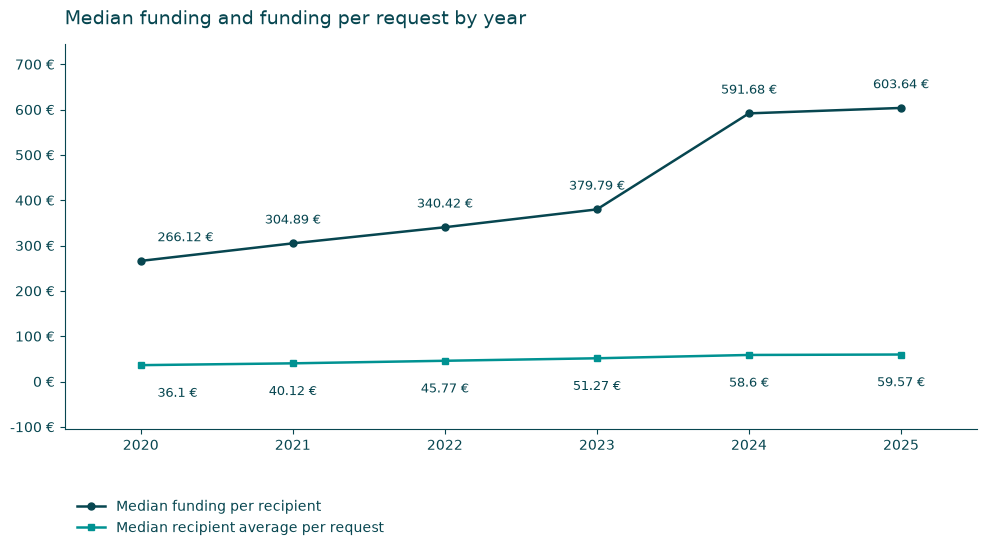

tax_year,median_pmd_eur,median_annual_amount_per_request,recipients_with_amount,recipients_with_valid_ratio
2020,266.12 €,36.1 €,"23,240","23,233"
2021,304.89 €,40.12 €,"22,798","22,779"
2022,340.42 €,45.77 €,"22,147","22,128"
2023,379.79 €,51.27 €,"22,555","22,535"
2024,591.68 €,58.6 €,"14,511","14,501"
2025,603.64 €,59.57 €,"15,483","15,483"


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from chart_style import finish_chart

recipient_year = overview_recipient_year.copy()

median_comparison = (
    recipient_year.groupby("tax_year")
    .agg(
        median_pmd_eur=("amount", "median"),
        median_annual_amount_per_request=("amount_per_request", "median"),
        recipients_with_amount=("amount", "count"),
        recipients_with_valid_ratio=("amount_per_request", "count"),
    )
    .reindex(range(2020, 2026))
    .rename_axis("tax_year")
    .reset_index()
)

def format_euros(value):
    return f"{value:,.2f}".rstrip("0").rstrip(".") + " €"

fig, ax = plt.subplots(figsize=(10, 6))

series = [
    (
        "median_pmd_eur",
        "Median funding per recipient",
        CHART_COLORS["primary"],
        "o",
        12,
    ),
    (
        "median_annual_amount_per_request",
        "Median recipient average per request",
        CHART_COLORS["secondary"],
        "s",
        -16,
    ),
]

for column, label, color, marker, vertical_offset in series:
    ax.plot(
        median_comparison["tax_year"],
        median_comparison[column],
        label=label,
        color=color,
        marker=marker,
    )

    observed = median_comparison.dropna(subset=[column])

    for i, (_, row) in enumerate(observed.iterrows()):
        first_point = i == 0

        ax.annotate(
            format_euros(row[column]),
            xy=(row["tax_year"], row[column]),
            xytext=(12, vertical_offset) if first_point
            else (0, vertical_offset),
            textcoords="offset points",
            ha="left" if first_point else "center",
            va="bottom" if vertical_offset > 0 else "top",
            fontsize=9,
            color=CHART_COLORS["foreground"],
        )

ax.set_title("Median funding and funding per request by year")
ax.set_xticks(range(2020, 2026))
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: format_euros(value))
)
ax.grid(False, which="both")
ax.margins(x=0.10, y=0.25)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0, -0.15),
    frameon=False,
)

finish_chart(fig)

display(
    median_comparison.style
    .format({
        "tax_year": "{:.0f}",
        "median_pmd_eur": format_euros,
        "median_annual_amount_per_request": format_euros,
        "recipients_with_amount": "{:,.0f}",
        "recipients_with_valid_ratio": "{:,.0f}",
    }, na_rep="Unavailable")
    .hide(axis="index")
)

### What the chart shows

Both measures increased between 2020 and 2025, but total funding per recipient grew faster than funding per request.

- **Median funding per recipient** rose from **€266.12 to €603.64**, an increase of **126.8%**.
- **Median recipient average per request** rose from **€36.10 to €59.57**, an increase of **65.0%**.
- **2023–2024:** median recipient funding jumped by **55.8%**, while the per-request measure increased more gradually, by **14.3%**.
- **2024–2025:** both measures grew only slightly, by approximately **2.0%** and **1.7%**, respectively.

### What this suggests

Higher funding per request accompanied the rise in recipient funding, but the two measures did not increase at the same pace. Changes in request numbers and in which recipients were included may also help explain the difference.

The sharp rise in median recipient funding in 2024 coincided with the legal-form eligibility change. Comparing the same organizations before and after that change would help distinguish funding increases from changes in the recipient population.

### How to read the lower line

For each recipient, annual funding is divided by its request count. The lower line shows the median of those recipient averages, giving each recipient equal weight.

It is **not the median of individual request amounts**, and its increase does not establish that supporters became wealthier or more generous. Dividing the two lines also does not give the typical number of requests, because their medians may represent different recipients.

**Note:** Recipients without positive request counts are excluded from the per-request measure. Amounts are not adjusted for inflation.

### How many recipients have zero recorded funding?

The chart counts unique recipients whose recorded annual funding is exactly zero. Missing funding and absent records are not treated as zero. Counts include amounts set to zero under the project's correction policy; the accompanying percentage uses recipients with known funding as its denominator.

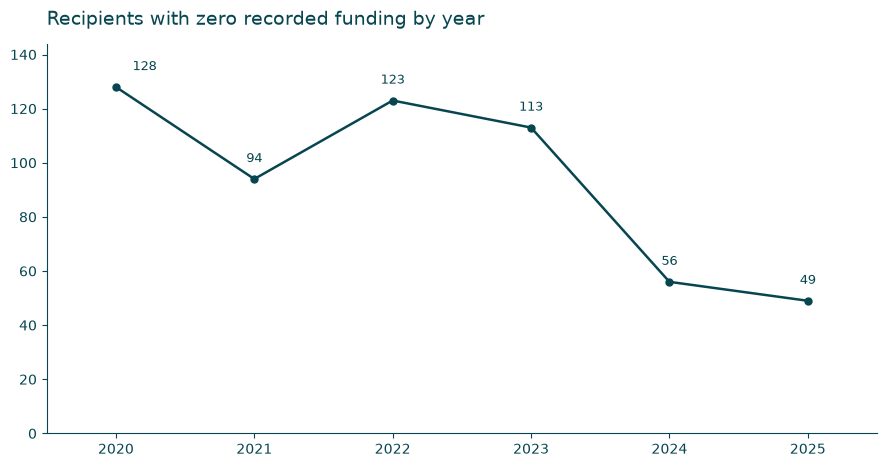

tax_year,zero_funding_recipients,recipients_with_known_funding,total_recipients,zero_funding_share
2020,128,"23,240","23,240",0.6%
2021,94,"22,798","22,798",0.4%
2022,123,"22,147","22,147",0.6%
2023,113,"22,555","22,555",0.5%
2024,56,"14,511","14,511",0.4%
2025,49,"15,483","15,483",0.3%


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from chart_style import finish_chart

recipient_year = overview_recipient_year.copy()

# Missing amounts remain unknown, rather than becoming zero.
recipient_year["zero_funding"] = recipient_year["amount"].eq(0)

zero_funding_summary = (
    recipient_year.groupby("tax_year")
    .agg(
        zero_funding_recipients=("zero_funding", "sum"),
        recipients_with_known_funding=("amount", "count"),
        total_recipients=("recipient_code", "nunique"),
    )
    .reindex(range(2020, 2026))
    .rename_axis("tax_year")
    .reset_index()
)

zero_funding_summary["zero_funding_share"] = (
    zero_funding_summary["zero_funding_recipients"]
    / zero_funding_summary["recipients_with_known_funding"].where(
        zero_funding_summary["recipients_with_known_funding"] > 0
    )
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    zero_funding_summary["tax_year"],
    zero_funding_summary["zero_funding_recipients"],
    marker="o",
    color=CHART_COLORS["primary"],
)

observed = zero_funding_summary.dropna(
    subset=["zero_funding_recipients"]
)

for i, (_, row) in enumerate(observed.iterrows()):
    ax.annotate(
        f"{row['zero_funding_recipients']:,.0f}",
        xy=(row["tax_year"], row["zero_funding_recipients"]),
        xytext=(12, 10) if i == 0 else (0, 10),
        textcoords="offset points",
        ha="left" if i == 0 else "center",
        va="bottom",
        fontsize=9,
        color=CHART_COLORS["foreground"],
    )

ax.set_title("Recipients with zero recorded funding by year")
ax.set_xticks(range(2020, 2026))
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: f"{value:,.0f}")
)
ax.grid(False, which="both")
ax.margins(x=0.10, y=0.20)

ax.grid(False, which="both")
ax.margins(x=0.10, y=0.20)
ax.set_ylim(bottom=0)

finish_chart(fig)

display(
    zero_funding_summary.style
    .format({
        "tax_year": "{:.0f}",
        "zero_funding_recipients": "{:,.0f}",
        "recipients_with_known_funding": "{:,.0f}",
        "total_recipients": "{:,.0f}",
        "zero_funding_share": "{:.1%}",
    }, na_rep="Unavailable")
    .hide(axis="index")
)

### What the chart shows

The number of recipients with zero recorded funding decreased overall, with the sharpest fall in 2024.

- **2020–2023:** counts fluctuated between **94 and 128 recipients**.
- **2023–2024:** the count fell from **113 to 56**, a decrease of **50.4%**.
- **2024–2025:** it fell further to **49**, the lowest count in the period.
- **Across 2020–2025:** the count decreased by **79 recipients (61.7%)**.

### How to interpret the decline

The 2024 decline coincided with the legal-form eligibility change and the reduction in the overall recipient population. Some zero-funded recipients may have left the dataset, rather than started receiving funding.

Zero-funded recipients also became a smaller share of all recorded recipients: approximately **0.55% in 2020**, compared with **0.32% in 2025**.

The chart alone cannot tell whether previously zero-funded organizations gained funding, became ineligible, or were no longer recorded. Following the same recipient codes across years would clarify these outcomes.

**Note:** Zero amounts include values set to zero under the project’s correction policy. Missing records are not counted as zero. Annual counts should not be added together to estimate unique organizations, because the same recipient may appear in several years.

## How widely do recipient-year amounts vary?

The statistics include recorded zero amounts. The following histogram includes only finite positive amounts and uses logarithmically spaced bins, so equally wide bars cover equal ratios rather than equal euro intervals. Its height counts recipient-year records, not distinct organizations.

In [16]:
pmd_distribution_summary = (
    overview_recipient_year["amount"]
    .dropna()
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .to_frame(name="Calculated PMD")
    .rename(index={
        "count": "Recipient-year records",
        "mean": "Average",
        "std": "Standard deviation",
        "min": "Minimum",
        "25%": "25th percentile",
        "50%": "Median",
        "75%": "75th percentile",
        "90%": "90th percentile",
        "95%": "95th percentile",
        "99%": "99th percentile",
        "max": "Maximum",
    })
)

display(
    pmd_distribution_summary.style
    .format(
        "{:,.0f} €",
        subset=pd.IndexSlice[
            pmd_distribution_summary.index != "Recipient-year records",
            ["Calculated PMD"],
        ],
        na_rep="Unavailable",
    )
    .format(
        "{:,.0f}",
        subset=pd.IndexSlice[
            ["Recipient-year records"],
            ["Calculated PMD"],
        ],
    )
)

,Calculated PMD
Recipient-year records,"120,734"
Average,"1,571 €"
Standard deviation,"21,249 €"
Minimum,0 €
25th percentile,137 €
Median,375 €
75th percentile,954 €
90th percentile,"2,147 €"
95th percentile,"3,657 €"
99th percentile,"12,782 €"


### Which funding ranges occur most often?

The histogram counts recipient-year records in 50 logarithmically spaced funding ranges. Only positive, finite amounts can appear on its logarithmic axis. The caption reports exclusions; records remain in the shared dataset.

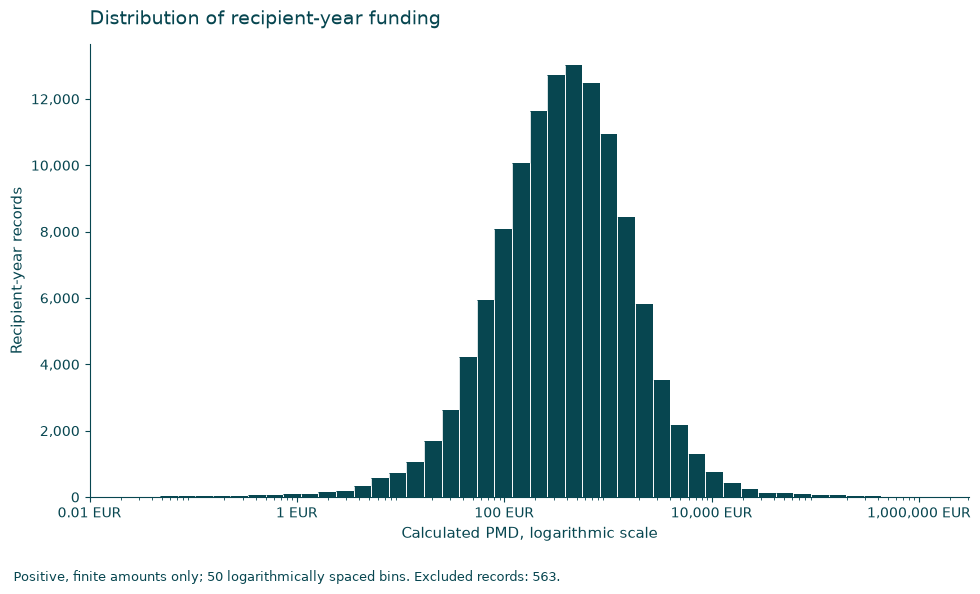

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from chart_style import finish_chart

amounts = overview_recipient_year["amount"]

plot_data = amounts.loc[np.isfinite(amounts) & amounts.gt(0)]

if plot_data.nunique() < 2:
    raise ValueError("At least two distinct positive amounts are required.")

bin_edges = np.geomspace(plot_data.min(), plot_data.max(), 51)

fig, ax = plt.subplots(figsize=(10, 6))

counts, edges, bars = ax.hist(
    plot_data,
    bins=bin_edges,
    color=CHART_COLORS["primary"],
    edgecolor="none",
    linewidth=0,
)

# Light separators appear only within the filled bin areas.
for count, left, right in zip(counts, edges[:-1], edges[1:]):
    if count > 0:
        ax.vlines(
            [left, right],
            ymin=0,
            ymax=count,
            colors="white",
            linewidth=0.6,
            zorder=3,
        )

ax.set_xscale("log")
ax.set_xlim(bin_edges[0], bin_edges[-1])
ax.set_title("Distribution of recipient-year funding")
ax.set_xlabel("Calculated PMD, logarithmic scale")
ax.set_ylabel("Recipient-year records")
ax.grid(False, which="both")

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda value, pos:
        f"{value:,.2f}".rstrip("0").rstrip(".") + " €"
    )
)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: f"{value:,.0f}")
)

finish_chart(
    fig,
    "Positive, finite amounts only; 50 logarithmically spaced bins. "
    f"Excluded records: {len(amounts) - len(plot_data):,}.",
)

### What the chart shows

Each bar counts recipient-year records within a funding range. Moving right means larger funding amounts; taller bars mean more records in that range.

- **Funding amounts are most commonly in the hundreds to low thousands of euros**, where the tallest bars appear.
- **Very large amounts are much less common**, but some extend into the millions.
- The bars show how often amounts occur, not how much of the total funding each range receives.

### Main takeaway

Most recorded amounts are relatively modest, while a few are exceptionally large. These large amounts can pull the average upward, making the **median more representative of typical recipient funding**.

**Note:** The funding axis is logarithmic, so bins become wider in euro terms towards the right. The chart combines 2020–2025; one organization can contribute a record in each year. The 563 nonpositive or invalid amounts are excluded from this chart only.

## How are requests and funding related?

Each point is a recipient-year with positive requests and funding. Both axes are logarithmic. The relationship is descriptive: funding is requests multiplied by average funding per request, and requests are not necessarily unique supporters.

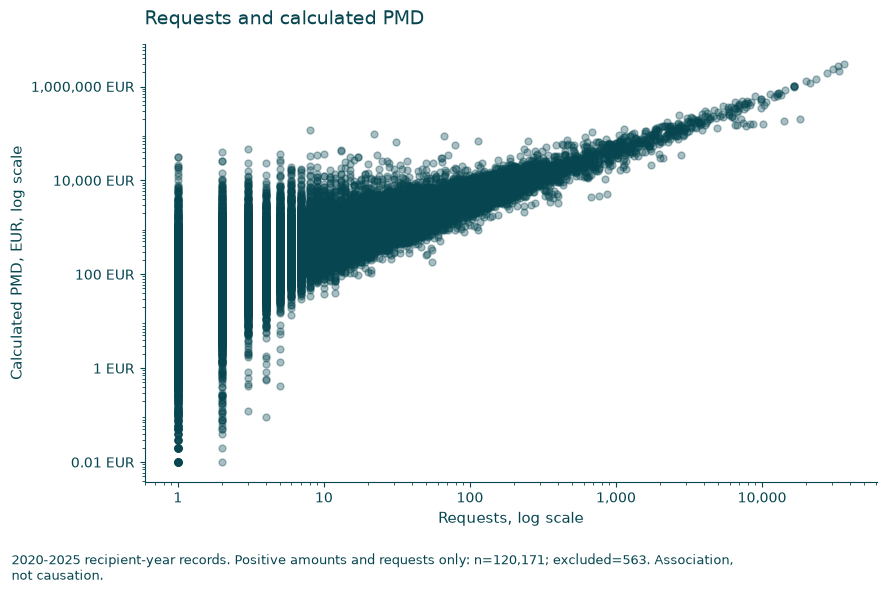

In [18]:
from chart_style import finish_chart, growth_boxplot, contrast_text

scatter_df = overview_recipient_year.loc[
    np.isfinite(overview_recipient_year['requests'])
    & np.isfinite(overview_recipient_year['amount'])
    & overview_recipient_year['requests'].gt(0)
    & overview_recipient_year['amount'].gt(0)
].copy()

plt.figure(figsize=(9, 6))
plt.scatter(
    scatter_df["requests"],
    scatter_df["amount"],
    alpha=0.35,
    color=CHART_COLORS["primary"]
)

plt.xscale("log")
plt.yscale("log")
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y:,.0f} €"))

plt.title("Requests and calculated PMD")
plt.xlabel("Requests, log scale")
plt.ylabel("Calculated PMD, EUR, log scale")
plt.grid(False, which="both")

finish_chart(plt.gcf(), f"2020-2025 recipient-year records. Positive amounts and requests only: n={len(scatter_df):,}; excluded={len(overview_recipient_year)-len(scatter_df):,}. Association, not causation.")



### What the chart shows

Each dot represents one organization in one year. Moving right means more requests; moving up means more funding.

- **More requests generally go together with higher funding**, creating the upward pattern.
- **The same request count can produce very different funding totals.** The vertical spread shows that average funding per request varies between organizations and years.
- The vertical stripes on the left occur because request counts are whole numbers: one, two, three and so on.

### Main takeaway

Both **request numbers and funding per request** matter. A high request count usually accompanies a large funding total, but request numbers alone do not explain all the differences.

**Note:** Both axes are logarithmic, so equal distances represent proportional increases. The chart combines 2020–2025 and does not track individual organizations’ growth. Requests are not necessarily unique supporters; 563 records without positive, finite funding and request values are excluded.

### How much funding does a request generate on average?

The overall average divides all recorded annual funding by all recorded requests. The comparison line is the median of each recipient's funding-per-request average, giving each valid recipient equal weight. Neither line is the median of individual request amounts. Zero-request recipients remain in the annual totals but have no individual ratio; missing amounts or counts make the corresponding overall total unavailable. The table reports the sample used for the recipient median.

Differences between the lines describe different weighting, not evidence about supporter wealth or causal growth drivers.

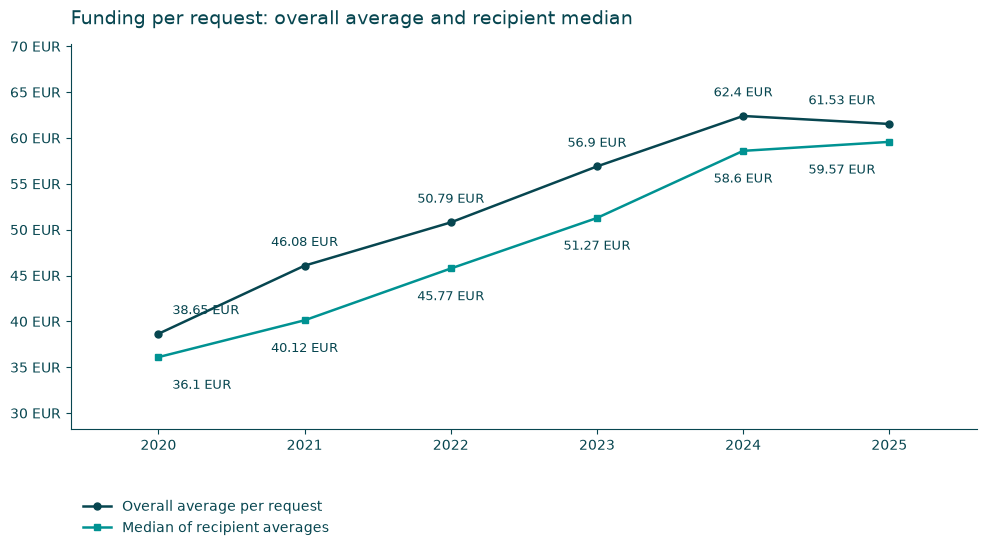

,Total funding (EUR),Total requests,Median recipient average (EUR),Valid recipient averages,Recorded recipients,Overall average (EUR)
Year,,,,,,
2020,"21,654,753.19 EUR","560,324",36.1 EUR,"23,233","23,240",38.65 EUR
2021,"27,843,175.86 EUR","604,259",40.12 EUR,"22,779","22,798",46.08 EUR
2022,"29,202,852.2 EUR","574,934",45.77 EUR,"22,128","22,147",50.79 EUR
2023,"33,985,135.12 EUR","597,309",51.27 EUR,"22,535","22,555",56.9 EUR
2024,"36,904,168.23 EUR","591,434",58.6 EUR,"14,501","14,511",62.4 EUR
2025,"40,124,624.74 EUR","652,119",59.57 EUR,"15,483","15,483",61.53 EUR


In [19]:
# Both totals use the full annual population; incomplete totals stay unavailable.
request_funding = overview_recipient_year.copy()
request_funding['recipient_average'] = request_funding['amount'].div(
    request_funding['requests'].where(request_funding['requests'].gt(0)))
request_value_summary = request_funding.groupby('tax_year').agg(
    total_funding=('amount', complete_total),
    total_requests=('requests', complete_total),
    median_recipient_average=('recipient_average', 'median'),
    valid_recipient_averages=('recipient_average', 'count'),
    recorded_recipients=('recipient_code', 'nunique'),
).reindex(range(2020, 2026))
request_value_summary['overall_average'] = request_value_summary['total_funding'].div(
    request_value_summary['total_requests'].where(request_value_summary['total_requests'].gt(0)))
fig, ax = plt.subplots(figsize=(10, 6))
for column, label, color, marker, offset in [
    ('overall_average', 'Overall average per request', CHART_COLORS['primary'], 'o', 12),
    ('median_recipient_average', 'Median of recipient averages', CHART_COLORS['secondary'], 's', -16),
]:
    ax.plot(request_value_summary.index, request_value_summary[column],
            label=label, color=color, marker=marker)
    for year, value in request_value_summary[column].dropna().items():
        ax.annotate(overview_euros(value), (year, value),
                    xytext=(10 if year == 2020 else -10 if year == 2025 else 0, offset),
                    textcoords='offset points',
                    ha='left' if year == 2020 else 'right' if year == 2025 else 'center',
                    va='bottom' if offset > 0 else 'top', fontsize=9,
                    color=CHART_COLORS['foreground'])
ax.set_title('Funding per request: overall average and recipient median')
ax.set_xticks(range(2020, 2026))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: overview_euros(value)))
ax.grid(False, which='both')
ax.margins(x=0.12, y=0.30)
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.15), frameon=False)
finish_chart(fig)
request_value_display = request_value_summary.rename(columns={
    'total_funding': 'Total funding (EUR)', 'total_requests': 'Total requests',
    'median_recipient_average': 'Median recipient average (EUR)',
    'valid_recipient_averages': 'Valid recipient averages',
    'recorded_recipients': 'Recorded recipients', 'overall_average': 'Overall average (EUR)',
}).rename_axis('Year')
display(request_value_display.style.format({
    **{c: overview_euros for c in request_value_display if '(EUR)' in c},
    **{c: '{:,.0f}' for c in request_value_display if '(EUR)' not in c},
}, na_rep='Unavailable'))


### What the chart shows

Funding per request increased substantially between 2020 and 2025, although the two measures moved in different directions in the final year.

- **Overall average per request:** rose from **€38.65 to €61.53**, an increase of approximately **59%**.
- **Median of recipient averages:** rose from **€36.10 to €59.57**, an increase of **65%**.
- **2024–2025:** the overall average fell slightly, from **€62.40 to €61.53**, while the recipient median continued to rise.

### How to interpret the difference

The overall average divides total funding by total requests. Organizations with more requests carry more weight in this measure.

The recipient median finds the middle value after calculating each organization's average funding per request. Each organization has equal weight, regardless of its request count.

The different directions in 2025 show that a falling overall average can coexist with a rising recipient median. Changes in recipient composition, request volumes and individual funding-per-request averages could explain this; the chart alone cannot identify which mattered most.

**Main takeaway:** Funding per request was considerably higher in 2025 than in 2020, but the latest change was not uniform across the two measures.

**Note:** Neither line shows the median of individual request amounts. Values are not adjusted for inflation, and the recipient population changes over time.

## How does funding per request vary?

Each observation represents one recipient in one year. Its average funding per request is calculated as annual funding divided by annual requests.

The statistics and histogram describe these recipient-level averages across 2020–2025. The line chart compares their annual mean and median. Each recipient-year receives equal weight; organizations recorded in several years contribute several observations to the pooled distribution.

Known, nonnegative funding and positive request counts are required. Missing values and zero request counts are excluded. Zero funding with positive requests remains a valid average of zero.

Statistic,Value
Recipient-year observations,"120,659"
Mean,68.17 €
Standard deviation,253.04 €
Minimum,0 €
10th percentile,20.93 €
25th percentile,31.95 €
Median,46.74 €
75th percentile,68.69 €
90th percentile,103.95 €
95th percentile,146.86 €


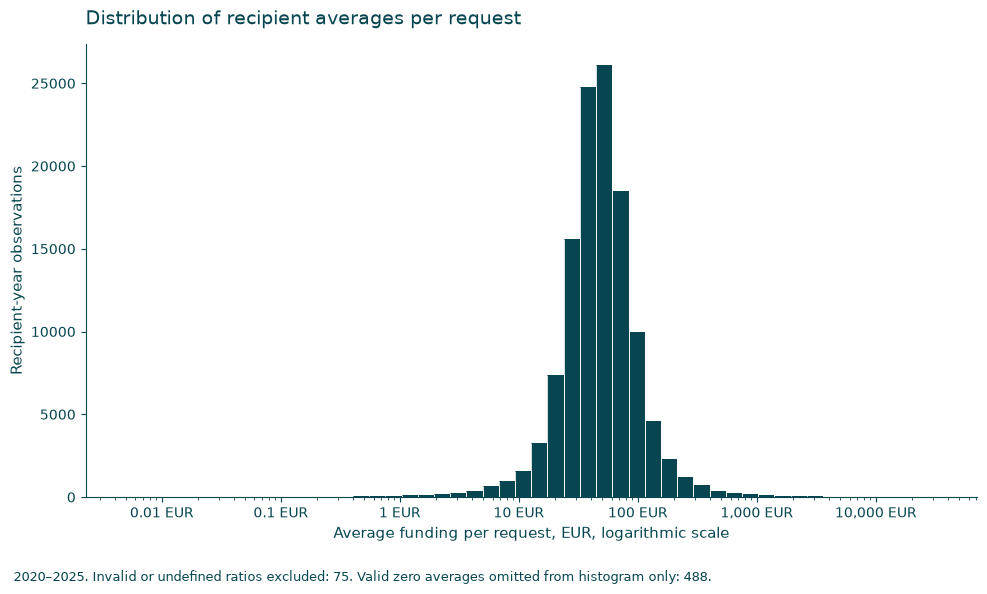

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from chart_style import finish_chart

data = overview_recipient_year
valid = (
    np.isfinite(data["amount"]) & data["amount"].ge(0)
    & np.isfinite(data["requests"]) & data["requests"].gt(0)
)
request_amounts = data.loc[
    valid, ["recipient_code", "tax_year", "amount", "requests"]
].copy()
request_amounts["average_per_request"] = (
    request_amounts["amount"] / request_amounts["requests"]
)

def euros(value):
    return f"{value:,.2f}".rstrip("0").rstrip(".") + " €"

values = request_amounts["average_per_request"]
statistics = values.describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)
labels = {
    "count": "Recipient-year observations", "mean": "Mean",
    "std": "Standard deviation", "min": "Minimum", "max": "Maximum",
    "10%": "10th percentile", "25%": "25th percentile",
    "50%": "Median", "75%": "75th percentile",
    "90%": "90th percentile", "95%": "95th percentile",
    "99%": "99th percentile",
}
display(pd.DataFrame({
    "Statistic": [labels.get(k, k) for k in statistics.index],
    "Value": [
        "Unavailable" if pd.isna(v) else
        f"{v:,.0f}" if k == "count" else euros(v)
        for k, v in statistics.items()
    ],
}).style.hide(axis="index"))

positive = values.loc[values.gt(0)]
if positive.nunique() < 2:
    raise ValueError("At least two distinct positive averages are required.")

fig, ax = plt.subplots(figsize=(10, 6))
counts, edges, _ = ax.hist(
    positive, bins=np.geomspace(positive.min(), positive.max(), 51),
    color=CHART_COLORS["primary"], edgecolor="none",
)
for count, left, right in zip(counts, edges[:-1], edges[1:]):
    if count > 0:
        ax.vlines([left, right], 0, count, color="white", linewidth=0.6)
ax.set_xscale("log")
ax.set_title("Distribution of recipient averages per request")
ax.set_xlabel("Average funding per request, EUR, logarithmic scale")
ax.set_ylabel("Recipient-year observations")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: euros(x)))
ax.grid(False, which="both")
finish_chart(
    fig,
    f"2020–2025. Invalid or undefined ratios excluded: {(~valid).sum():,}. "
    f"Valid zero averages omitted from histogram only: {values.eq(0).sum():,}.",
)

### What the chart shows

Each observation represents one recipient’s average funding per request in one year, calculated as annual funding divided by annual requests.

- **The tallest bars are around several tens of euros per request.** This is where recipient-year averages occur most frequently.
- **Averages of several hundred or thousands of euros are much less common**, but create a long upper tail.
- Very small positive averages also occur, although relatively infrequently.

### Main takeaway

Most recipient-year averages cluster around tens of euros per request, while a small number are exceptionally high. These high values can pull the mean upward, making the median useful for describing the middle recipient.

An unusually high average is worth examining alongside its request count: one large request can strongly affect an organization with few requests. The chart alone does not establish why averages differ or indicate supporter wealth.

**Note:** The horizontal axis is logarithmic. These are recipient averages, not individual request amounts. The chart pools 2020–2025, so it cannot show which part of the distribution grew over time. It excludes 75 invalid or undefined ratios and omits 488 valid zero averages from the histogram only.

### How do the mean and median change over time?

The mean and median below summarize recipients’ annual average funding per request. Both give each valid recipient equal weight.

The mean is sensitive to unusually high averages; the median describes the middle recipient. A larger gap suggests that high values pull the mean above the middle, but does not by itself explain which recipients experienced growth.

This mean differs from total funding divided by total requests, which weights recipient averages by request counts. Neither measure is the median of individual request amounts.

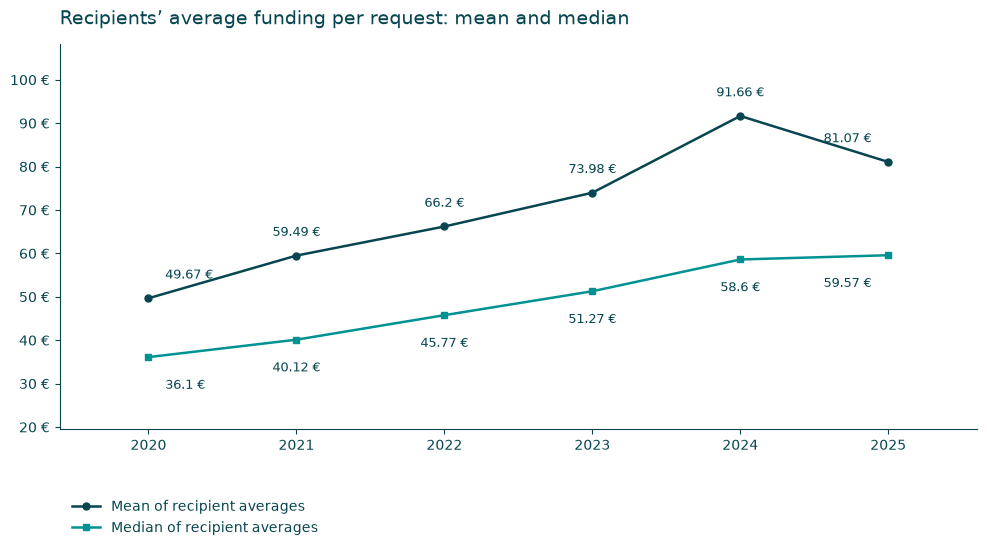

,mean,median,observations
Year,,,
2020,49.67 €,36.1 €,"23,233"
2021,59.49 €,40.12 €,"22,779"
2022,66.2 €,45.77 €,"22,128"
2023,73.98 €,51.27 €,"22,535"
2024,91.66 €,58.6 €,"14,501"
2025,81.07 €,59.57 €,"15,483"


In [25]:
annual_request_amounts = (
    request_amounts.groupby("tax_year")["average_per_request"]
    .agg(mean="mean", median="median", observations="count")
    .reindex(ANALYSIS_YEARS)
)

fig, ax = plt.subplots(figsize=(10, 6))
for column, label, color, marker, offset in [
    ("mean", "Mean of recipient averages", CHART_COLORS["primary"], "o", 12),
    ("median", "Median of recipient averages", CHART_COLORS["secondary"], "s", -16),
]:
    ax.plot(
        annual_request_amounts.index, annual_request_amounts[column],
        label=label, color=color, marker=marker,
    )
    for year, value in annual_request_amounts[column].dropna().items():
        first, last = year == ANALYSIS_YEARS[0], year == ANALYSIS_YEARS[-1]
        ax.annotate(
            euros(value), (year, value),
            xytext=(12 if first else -12 if last else 0, offset),
            textcoords="offset points",
            ha="left" if first else "right" if last else "center",
            va="bottom" if offset > 0 else "top",
            fontsize=9, color=CHART_COLORS["foreground"],
        )

ax.set_title("Recipients’ average funding per request: mean and median")
ax.set_xticks(ANALYSIS_YEARS)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: euros(x)))
ax.grid(False, which="both")
ax.margins(x=0.12, y=0.30)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15), frameon=False)
finish_chart(fig)

display(
    annual_request_amounts.rename_axis("Year").style.format({
        "mean": euros, "median": euros, "observations": "{:,.0f}",
    }, na_rep="Unavailable")
)

### What the chart shows

The chart compares the mean and median of recipients’ annual average funding per request. Each recipient has equal weight, regardless of its request count.

- **The median increased every year**, from **€36.10 in 2020 to €59.57 in 2025**, a rise of approximately **65%**. The middle of the recipient distribution moved steadily upward.
- **The mean remained above the median throughout**, indicating that high recipient averages pulled it upward.
- **2024 showed the largest gap:** the mean reached **€91.66**, compared with a median of **€58.60**.
- **In 2025, the measures moved in opposite directions:** the mean fell by **11.6%** to **€81.07**, while the median increased by **1.7%** to **€59.57**.

### Main takeaway

The middle recipient’s average funding per request increased steadily, but the mean was more variable. Its decline in 2025 did not represent a decline at the middle of the distribution.

The narrowing gap in 2025 is consistent with a reduced influence of high recipient averages. However, the chart cannot distinguish falling averages within existing recipients from changes in which recipients were included. Annual percentiles and matched-recipient comparisons would help explain this.

**Note:** These are summaries of recipient-level averages, not individual request amounts. The mean is not total funding divided by total requests. Valid zero averages are included; undefined ratios are excluded. Recipient populations change over time, and amounts are not adjusted for inflation.

### Which parts of the distribution changed?

Annual percentiles describe the spread of recipients’ average funding per request. The 10th percentile represents the lower end, the median the middle, and the 90th and 95th percentiles the upper end.

Recipients can differ between years. Changes in percentiles describe the distribution, not necessarily growth within the same organizations.

In [26]:
ratio_data = overview_recipient_year.loc[
    overview_recipient_year["amount"].notna()
    & overview_recipient_year["requests"].gt(0)
].copy()
ratio_data["ratio"] = ratio_data["amount"] / ratio_data["requests"]

annual_percentiles = (
    ratio_data.groupby("tax_year")["ratio"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
    .unstack()
    .rename(columns={
        0.10: "P10", 0.25: "P25", 0.50: "Median",
        0.75: "P75", 0.90: "P90", 0.95: "P95",
    })
    .reindex(ANALYSIS_YEARS)
)
display(annual_percentiles.style.format("{:,.2f} €", na_rep="Unavailable"))

percentile_changes = pd.DataFrame({
    "2024": annual_percentiles.loc[2024],
    "2025": annual_percentiles.loc[2025],
})
percentile_changes["Euro change"] = (
    percentile_changes["2025"] - percentile_changes["2024"]
)
percentile_changes["Percentage change"] = (
    percentile_changes["Euro change"]
    / percentile_changes["2024"].where(percentile_changes["2024"] > 0)
)
display(percentile_changes.style.format({
    "2024": "{:,.2f} €", "2025": "{:,.2f} €",
    "Euro change": "{:+,.2f} €", "Percentage change": "{:+.1%}",
}, na_rep="Unavailable"))

,P10,P25,Median,P75,P90,P95
tax_year,,,,,,
2020,16.52 €,25.12 €,36.10 €,52.48 €,80.04 €,109.53 €
2021,19.05 €,28.39 €,40.12 €,57.94 €,88.71 €,126.56 €
2022,21.16 €,32.35 €,45.77 €,66.40 €,101.03 €,143.59 €
2023,24.39 €,36.40 €,51.27 €,73.00 €,109.90 €,154.82 €
2024,28.51 €,42.04 €,58.60 €,83.61 €,129.30 €,185.99 €
2025,29.57 €,42.75 €,59.57 €,83.36 €,121.51 €,168.95 €


,2024,2025,Euro change,Percentage change
P10,28.51 €,29.57 €,+1.06 €,+3.7%
P25,42.04 €,42.75 €,+0.71 €,+1.7%
Median,58.60 €,59.57 €,+0.98 €,+1.7%
P75,83.61 €,83.36 €,-0.25 €,-0.3%
P90,129.30 €,121.51 €,-7.80 €,-6.0%
P95,185.99 €,168.95 €,-17.04 €,-9.2%


### How did different parts of the distribution change?

Each line follows a percentile of recipients’ annual average funding per request. The median describes the middle, while P10 and P95 describe the lower and upper parts of the distribution.

Rising lines indicate higher values at those positions. A widening gap between P25 and P75 means the middle half of recipient averages became more spread out.

**Note:** Each valid recipient has equal weight within a year. The lines do not track the same organizations or individual requests; recipient composition can change between years.

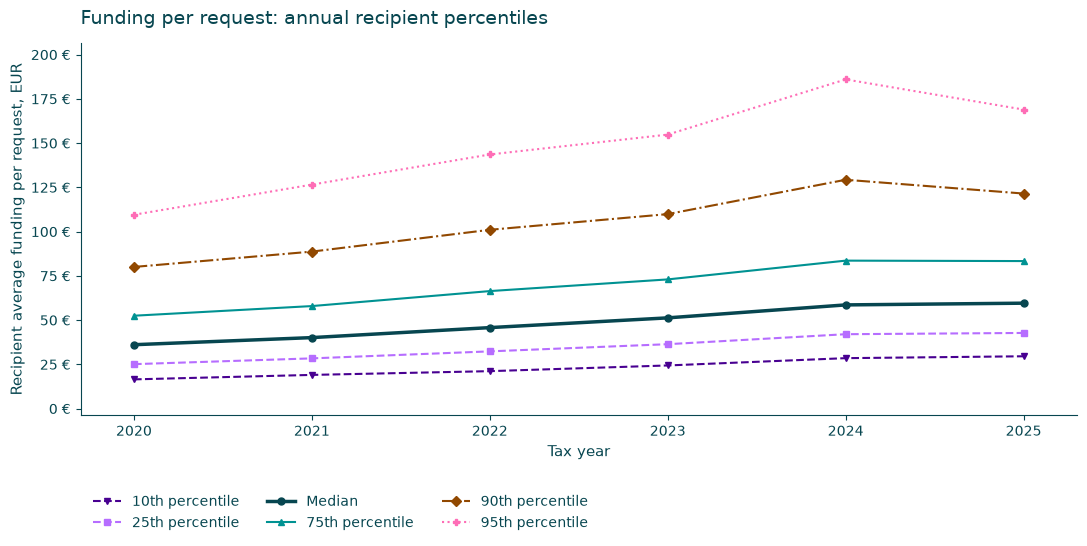

In [27]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from chart_style import finish_chart

fig, ax = plt.subplots(figsize=(11, 6))

# Colors follow the project's colorblind-safe theme.
series = [
    ("P10", "10th percentile", "#480091", "v", "--"),
    ("P25", "25th percentile", "#B66DFF", "s", "--"),
    ("Median", "Median", CHART_COLORS["primary"], "o", "-"),
    ("P75", "75th percentile", CHART_COLORS["secondary"], "^", "-"),
    ("P90", "90th percentile", "#914800", "D", "-."),
    ("P95", "95th percentile", "#FE6DB6", "P", ":"),
]

for column, label, color, marker, linestyle in series:
    ax.plot(
        annual_percentiles.index,
        annual_percentiles[column],
        label=label,
        color=color,
        marker=marker,
        linestyle=linestyle,
        linewidth=2.5 if column == "Median" else 1.5,
        markersize=5,
    )

ax.set_title("Funding per request: annual recipient percentiles")
ax.set_xlabel("Tax year")
ax.set_ylabel("Recipient average funding per request, EUR")
ax.set_xticks(ANALYSIS_YEARS)
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, pos:
        f"{value:,.2f}".rstrip("0").rstrip(".") + " €"
    )
)
ax.grid(False, which="both")
ax.margins(x=0.06, y=0.12)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0, -0.18),
    ncol=3,
    frameon=False,
)

finish_chart(fig)

### What the chart shows

Funding per request increased across the lower, middle and upper parts of the recipient distribution between 2020 and 2024. In 2025, the pattern changed.

- **2020–2024:** all displayed percentiles rose. The increase was not limited to the highest recipient averages.
- **The upper percentiles rose more in euro terms.** The 95th percentile increased from roughly **€110 to €186**, while the median rose from **€36 to €59**.
- **2024–2025:** the 90th and 95th percentiles fell, while the lower percentiles and median increased slightly. The 75th percentile remained approximately unchanged.
- **All displayed percentiles remained above their 2020 levels in 2025.**

### Main takeaway

The 2025 decline was visible at the upper end of the distribution, not at its middle. This helps explain why the mean of recipient averages fell while the median continued to rise.

However, falling upper percentiles do not prove that the same high-average organizations received less per request. Changes in which recipients were included could also contribute. Comparing matched recipients would help distinguish these explanations.

**Note:** These are percentiles of recipients’ annual average funding per request, not individual request amounts. Each valid recipient has equal weight within a year. Values quoted from the chart are approximate.

## Where are recipient organizations registered?

The table sums funding and requests across years by municipality. The summary's median_recipients_per_year is a median annual count. The chart's n labels and supporting unique_recipients column instead count distinct recipients across 2020-2025 within each municipality; a recipient recorded in different municipalities can appear in more than one municipal count. The chart shows the 15 municipalities with the largest recorded totals, without population adjustment; it does not locate the people providing support.

In [20]:
municipality_records = overview_recipient_year.copy()
municipality_records['municipality'] = (
    municipality_records['recipient_municipality'].astype('string').str.strip()
    .replace('', pd.NA).fillna('Unknown')
)
municipality_year = municipality_records.groupby(['municipality', 'tax_year']).agg(
    recipients=('recipient_code', 'nunique'))
municipality_summary = municipality_records.groupby('municipality', as_index=False).agg(
    total_pmd_eur=('amount', complete_total),
    total_requests=('requests', complete_total),
    unique_recipients=('recipient_code', 'nunique'),
    missing_amounts=('amount', lambda s: s.isna().sum()),
    missing_requests=('requests', lambda s: s.isna().sum()),
)
municipality_summary['median_recipients_per_year'] = municipality_summary['municipality'].map(
    municipality_year.groupby(level='municipality')['recipients'].median())
municipality_summary = municipality_summary.sort_values('total_pmd_eur', ascending=False)
display(municipality_summary.style.format({
    'total_pmd_eur': '{:,.2f} EUR', 'total_requests': '{:,.0f}',
    'unique_recipients': '{:,.0f}', 'missing_amounts': '{:,.0f}',
    'missing_requests': '{:,.0f}', 'median_recipients_per_year': '{:,.1f}',
}, na_rep='Unavailable').hide(axis='index'))


municipality,total_pmd_eur,total_requests,unique_recipients,missing_amounts,missing_requests,median_recipients_per_year
Vilniaus m. sav.,"94,489,390.93 EUR","1,650,304","8,281",0,0,"5,694.0"
Kauno m. sav.,"21,039,048.36 EUR","368,922","3,278",0,0,"2,377.5"
Vilniaus r. sav.,"7,781,088.54 EUR","137,694",767,0,0,498.0
Klaipėdos m. sav.,"7,770,261.77 EUR","158,902","1,415",0,0,"1,032.5"
Panevėžio m. sav.,"4,075,861.95 EUR","83,450","1,067",0,0,786.5
Kauno r. sav.,"3,762,745.84 EUR","64,859",851,0,0,581.5
Šiaulių m. sav.,"3,621,559.65 EUR","81,129","1,172",0,0,858.0
Alytaus m. sav.,"2,351,277.99 EUR","56,205",716,0,0,546.5
Klaipėdos r. sav.,"2,132,348.39 EUR","43,476",583,0,0,391.0
Šiaulių r. sav.,"2,126,958.16 EUR","47,977",341,0,0,248.5


### Which municipalities have the largest recorded funding totals?

The chart ranks the 15 largest complete six-year municipal funding totals. Labels show distinct recipients within each municipality across the period. Location means the recipient's recorded municipality, not the location of supporters or beneficiaries.

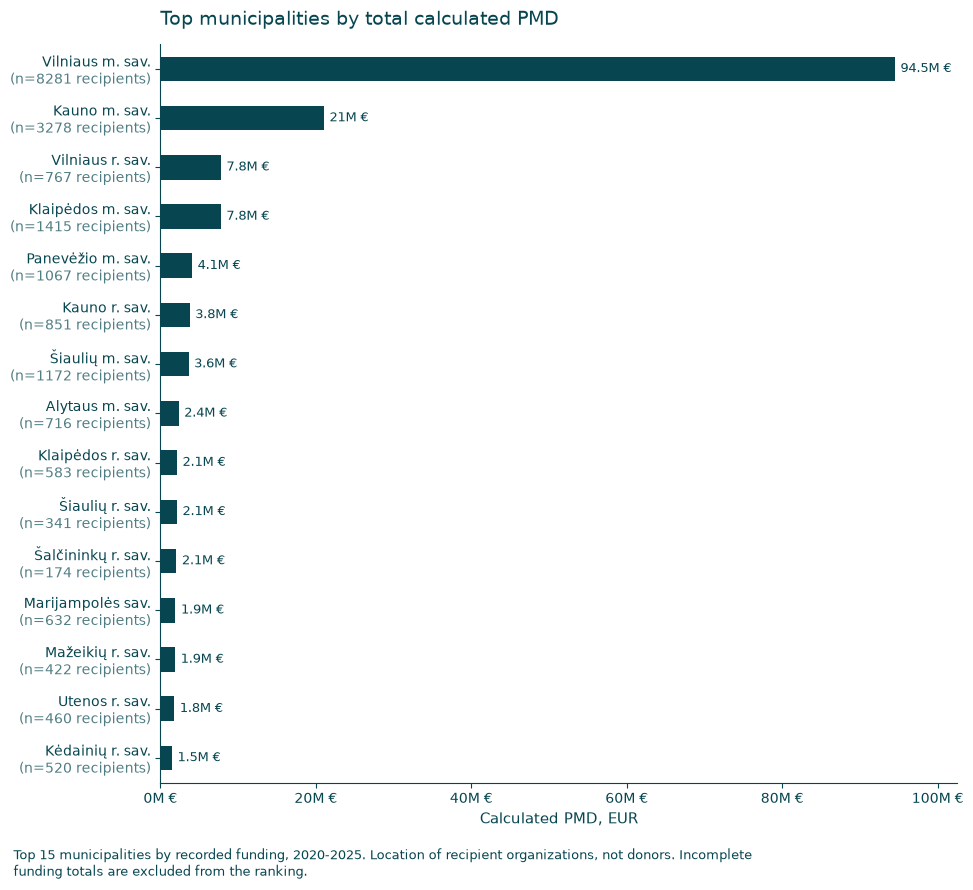

,municipality,total_pmd_eur,total_requests,unique_recipients,missing_amounts,missing_requests,median_recipients_per_year,municipality_label
22,Kėdainių r. sav.,1492827.81,34104,520,0,0,394.5,Kėdainių r. sav.\n(n=520 recipients)
45,Utenos r. sav.,1787258.14,43329,460,0,0,335.0,Utenos r. sav.\n(n=460 recipients)
25,Mažeikių r. sav.,1897754.81,43937,422,0,0,315.5,Mažeikių r. sav.\n(n=422 recipients)
24,Marijampolės sav.,1940267.48,44174,632,0,0,484.5,Marijampolės sav.\n(n=632 recipients)
53,Šalčininkų r. sav.,2057042.78,48828,174,0,0,128.0,Šalčininkų r. sav.\n(n=174 recipients)
55,Šiaulių r. sav.,2126958.16,47977,341,0,0,248.5,Šiaulių r. sav.\n(n=341 recipients)
19,Klaipėdos r. sav.,2132348.39,43476,583,0,0,391.0,Klaipėdos r. sav.\n(n=583 recipients)
1,Alytaus m. sav.,2351277.99,56205,716,0,0,546.5,Alytaus m. sav.\n(n=716 recipients)
54,Šiaulių m. sav.,3621559.65,81129,1172,0,0,858.0,Šiaulių m. sav.\n(n=1172 recipients)
15,Kauno r. sav.,3762745.84,64859,851,0,0,581.5,Kauno r. sav.\n(n=851 recipients)


In [21]:
from chart_style import finish_chart, growth_boxplot, contrast_text

plot_df = municipality_summary.dropna(subset=["total_pmd_eur"]).head(15).sort_values("total_pmd_eur", ascending=True)

plot_df = plot_df.copy()
plot_df["municipality_label"] = plot_df["municipality"] + "\n(n=" + plot_df["unique_recipients"].astype("Int64").astype(str) + " recipients)"

ax = plot_df.plot(
    kind="barh",
    x="municipality_label",
    y="total_pmd_eur",
    figsize=(10, 9),
    color=CHART_COLORS["primary"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{value/1_000_000:.1f}M €" for value in container.datavalues],
        fontsize=8,
        padding=4
    )

plt.title("Top municipalities by total calculated PMD")
plt.xlabel("Calculated PMD, EUR")
plt.ylabel("")
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x/1_000_000:.1f}M €"))

finish_chart(plt.gcf(), 'Top 15 municipalities by recorded funding, 2020-2025. Location of recipient organizations, not donors. Incomplete funding totals are excluded from the ranking.')


display(plot_df)


### What the chart shows

The chart ranks the 15 municipalities whose registered recipient organizations received the most funding across 2020–2025. The number below each municipality shows its unique recipients during that period.

- **Vilnius city leads by a large margin:** €94.5 million across 8,281 recipients, approximately **4.5 times** Kaunas city’s €21 million.
- **Recipient numbers do not fully explain the differences:** Vilnius district and Klaipėda city each received approximately €7.8 million, despite having 767 and 1,415 recipients respectively.
- Funding may be spread across many organizations or concentrated in a few large recipients; these totals do not show which.

### Main conclusion

Recorded funding is strongly concentrated among organizations registered in Vilnius city. However, this does **not** mean that Vilnius residents provided that funding or received all its benefits. Organizations registered there may attract support and operate across Lithuania.

Examining the largest recipients within each municipality would help explain whether a few organizations account for much of the difference.

**Note:** These are six-year totals, not annual amounts or population-adjusted comparisons. A recipient recorded in different municipalities over time may appear in more than one municipality’s count.

## Main findings

### More funding and requests, despite fewer recorded recipients

Total annual funding increased from **€21.65 million in 2020 to €40.12 million in 2025**, a rise of approximately **85.3%**. Over the same period, requests increased by **16.4%**, while recorded recipient numbers fell by **33.4%**.

The largest change occurred in 2024: recipient numbers fell by **35.7%**, while requests decreased by only **1.0%**. The [legal-form analysis](03_legal_forms_analysis.ipynb) discusses the eligibility changes relevant to this break. This overview alone does not establish why each organization disappeared from the records.

### Request activity reached its highest level in 2025

Requests increased by **60,685 (10.3%) in 2025**, reaching **652,119**, the highest count in the six-year period. Recorded recipient numbers also increased, by **6.7%**, to **15,483**.

This indicates greater recorded request activity. It could reflect more people participating, more requests from existing participants, or both. 

### Both recipient funding and funding per request increased

Median annual funding rose from **€266 to €604**, while overall average funding per request increased from **€38.65 to €61.53**. These increases describe changing annual, not necessarily growth within the same organizations.

In 2025, the overall average per request fell slightly while the median of recipient averages rose. 

### The typical recipient receives much less than the average funding

Median annual funding rose from **€266 in 2020 to €380 in 2023**, then increased to **€592 in 2024** and **€604 in 2025**.

In contrast, average funding was approximately **€2,591 per recipient in 2025**, more than four times the median. This large difference shows that high-funded organizations pull the average well above what a typical recipient receives.

The median provides a clearer picture of typical funding: half of recorded recipients received **€603.64 or less in 2025**, and half received that amount or more.

**Note:** These figures include zero-funded recipients. Changes over time reflect both changes in funding and changes in which organizations were included.

### The typical recipient still receives relatively few requests

Median requests remained at **7 during 2020–2023**, then increased to **9 in 2024–2025**. In contrast, the average was approximately **42 requests per recipient in 2025**. This large difference indicates that high-request organizations pull the average well above the typical recipient’s count.


### Large funding amounts are unusual but substantial

Most recipient-year amounts are in the hundreds to low thousands of euros, while a few reach millions. The median is therefore more representative of typical funding than the average.

The annual leader was **Mamų unija in 2020** (appearing one time in 2020) and **Mėlyna ir geltona in every year from 2021 to 2025**. 

### Funding is geographically concentrated by recipient address

Organizations registered in Vilnius city received approximately **€94.5 million**, nearly half of the **€189.7 million** recorded across all six years. This identifies where recipient organizations are registered, not where supporters live or where the funding benefits people.

## Questions raised by the findings

1. **How much of the rise in typical funding reflects gains within the same organizations?**  
   Matched-recipient comparisons in [notebook 07](07_growth_drivers_analysis.ipynb) help distinguish funding changes from changes in the recipient population. The [legal-form analysis](03_legal_forms_analysis.ipynb) provides context for the 2024 break.

2. **Were additional requests spread widely or concentrated among a few organizations?**  
   Recipient-level comparisons in notebook 07 can identify which organizations contributed most to the increase, including the sharp rise in 2025.

3. **Is funding becoming more concentrated over time?**  
   The [top-1% analysis](04_top_1_percent_overview.ipynb) provides a foundation for comparing annual funding shares of the largest recipients.

4. **Why did the two funding-per-request measures move in opposite directions in 2025?**  
   Further analysis in notebook 07 can distinguish changes in recipient-level averages from changes in request volumes and recipient composition.

5. **Do a few large organizations account for most of Vilnius city’s funding?**  
   A geographic extension of notebook 04’s concentration analysis could distinguish a few exceptionally large recipients from a broader municipal pattern.

## Reading the results together

Annual totals, recipient-year distributions and municipality totals answer different questions. Their different units of observation remain distinct throughout the comparisons.

[Previous notebook](00_data_inspection.ipynb) | [Next notebook](02_pmd_distribution.ipynb) | [Reading guide](../README.md#reading-order)